# GAT-v4 | Phase 9 — External Validation on CPTAC-KIRC

**Purpose:** Score the 15 TCGA-KIRC-trained GATv4 fold models (Phase 7 checkpoints)
on the independent CPTAC-KIRC cohort, with **zero refitting on CPTAC** — every
normalisation statistic, PPI edge, and risk-group threshold is carried over
exactly as it was fit on each fold's TCGA training split. This is what makes
it a genuine external-validation number rather than a second internal CV.

### Methodology
1. For each of the 15 TCGA CV folds: reload that fold's **training-tumor**
   RNA z-score stats, CNV centering mean, clinical stats, PPI edge set
   (`edge_index`/`edge_weight`), and trained model weights.
2. Build a CPTAC feature tensor **using those TCGA-train statistics** — CPTAC
   never contributes a mean, std, median, or edge weight of its own.
3. Run the fold's model on all CPTAC patients → risk scores.
4. Evaluate C-index, Integrated Brier Score, time-dependent AUC, and the
   log-rank test — all using baseline hazard / censoring KM / risk-group
   threshold fit on that fold's **TCGA training split**, exactly like the
   internal test-fold evaluation in Phase 7.
5. Ensemble the 15 fold-level risk scores (mean) into one external risk
   score per CPTAC patient and report a pooled summary.

### Required CPTAC inputs (edit paths in Cell 1 if yours differ)
This assumes your CPTAC preprocessing notebooks (Phases 1–4, adapted from the
KIRC pipeline) produced outputs in the **same shape/convention** as the TCGA
files consumed by Phases 2/3/6:

| File | Shape / columns | Notes |
|------|------------------|-------|
| `cptac_vst_matrix.csv` | genes × samples | Same log-scale normalisation family as TCGA VST. If your CPTAC RNA is TPM/FPKM, apply `log2(x+1)` (or your own VST) *before* this notebook — see Cell 3. |
| `cptac_cnv_raw.csv` | genes × samples | **Raw copy number**, diploid = `CPTAC_CNV_NEUTRAL_VALUE` (default 2.0) — not yet centered. This notebook converts it to the same "0 = neutral" convention as TCGA GISTIC2. |
| `cptac_clinical_clean.csv` | `patient_id, event, os_months, age, stage, grade` | Same encoding as TCGA: `event`∈{0,1}, `stage`/`grade`∈{1,2,3,4}. |
| `cptac_sample_alignment.csv` | `sample_id, patient_id, tissue_type, include` | `tissue_type=='tumor'` rows with `include==True` are used. |

### Critical caveats (read before trusting the numbers)
- **RNA cross-platform comparability**: TCGA VST and CPTAC's own normalisation
  are not guaranteed to be on the same scale. Applying TCGA's train-fold
  z-score stats to CPTAC assumes comparable expression scale; a large,
  systematic shift here will look like poor generalisation even if the
  biology transfers.
- **CNV convention mismatch**: TCGA CNV is GISTIC2-style, centered at 0. CPTAC
  copy-number calls are typically centered at 2 (diploid). This notebook
  subtracts `CPTAC_CNV_NEUTRAL_VALUE` and clips to GISTIC2's `[-2, 2]` range —
  a documented approximation, not an exact remapping.
- **Gene panel coverage**: only genes present in *both* the TCGA PPI node
  list and the CPTAC matrices contribute real signal; missing genes are
  imputed to the TCGA train-fold mean (RNA) / 0 (CNV), same convention Phase 6
  uses for TCGA genes absent from a given matrix.

---
| Cell | What |
|------|------|
| 1 | Imports, paths & CPTAC config |
| 2 | Load TCGA training artifacts (PPI gene index, CV folds, VST/CNV/clinical) |
| 3 | Load CPTAC external cohort |
| 4 | Model definition + evaluation metrics (verbatim from Phase 7) |
| 5 | Build per-fold CPTAC tensors from TCGA train-fold statistics |
| 6 | Run inference — 15 TCGA-trained models → CPTAC cohort |
| 7 | Ensemble across folds + aggregate external-validation metrics |
| 8 | KM plot, save results table + audit YAML |


---
## Cell 1 — Imports, Paths & CPTAC Config

**Edit `CPTAC_DATA_PROC` and the CNV-neutral constant if your CPTAC pipeline differs.**


In [1]:
import sys, json, yaml, hashlib, time
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
from scipy import stats
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv, global_mean_pool
from torch.cuda.amp import autocast
from tqdm.auto import tqdm

# ── TCGA project paths (same as Phases 0–8B) ──────────────────────────────────
PROJECT_ROOT = Path(r"C:\Users\jiyad\Desktop\PROJECT\KIRC\script")
KIRC_ROOT    = PROJECT_ROOT / "KIRC"
DATA_PROC    = KIRC_ROOT / "data" / "processed"
DATA_SPLITS  = KIRC_ROOT / "data" / "splits"
CKPT_DIR     = KIRC_ROOT / "results" / "checkpointsibsLOG"     # Phase 7 fold checkpoints
AUDIT_DIR    = KIRC_ROOT / "audit"

# ── Phase 9 (this notebook) output paths ──────────────────────────────────────
EXTVAL_DIR   = KIRC_ROOT / "results" / "external_validation_cptac"
EXTVAL_TABLE_DIR = EXTVAL_DIR / "tables"
for d in [EXTVAL_DIR, EXTVAL_TABLE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ── CPTAC data paths — EDIT THESE if your CPTAC preprocessing notebooks used
#    different filenames/locations ────────────────────────────────────────────
CPTAC_DATA_PROC = KIRC_ROOT / "data" / "cptac_processed"

CPTAC_VST_PATH        = CPTAC_DATA_PROC / "cptac_vst_matrix.csv"        # genes x samples
CPTAC_CNV_RAW_PATH    = CPTAC_DATA_PROC / "cptac_cnv_raw.csv"           # genes x samples, GISTIC2 discrete (from Phase C2)
CPTAC_CLINICAL_PATH   = CPTAC_DATA_PROC / "cptac_clinical_clean.csv"    # patient-level
CPTAC_ALIGNMENT_PATH  = CPTAC_DATA_PROC / "cptac_sample_alignment.csv"  # sample-level

# ── CNV convention: confirmed CPTAC source is cBioPortal data_cna.txt, already
#    GISTIC2 discrete (-2..2, neutral=0) — SAME convention as TCGA. Set to 0 so
#    the "conversion" below is a no-op. (If you ever switch to a raw diploid-
#    centered copy-number source instead, e.g. straight from GDC, set this to
#    2.0.) ──
CPTAC_CNV_NEUTRAL_VALUE = 0.0
GISTIC2_CLIP_RANGE      = (-2.0, 2.0)

if str(KIRC_ROOT) not in sys.path:
    sys.path.insert(0, str(KIRC_ROOT))
from src.utils.logger import get_logger
from src.config import (
    GAT_IN_DIM, GAT_HIDDEN, GAT_HEADS, GAT_MLP_HIDDEN,
    GAT_CLINICAL_DIM, GAT_DROPOUT, N_BOOTSTRAP, MASTER_SEED
)

log = get_logger('phase9_external_validation_cptac')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = (DEVICE.type == 'cuda')
EVAL_BATCH_SIZE = 64

print(f"Device            : {DEVICE}")
print(f"TCGA splits dir   : {DATA_SPLITS}")
print(f"TCGA checkpoints  : {CKPT_DIR}")
print(f"CPTAC data dir    : {CPTAC_DATA_PROC}")
print(f"Output dir        : {EXTVAL_DIR}")
for p, name in [(CPTAC_VST_PATH, 'CPTAC VST matrix'),
                (CPTAC_CNV_RAW_PATH, 'CPTAC CNV raw'),
                (CPTAC_CLINICAL_PATH, 'CPTAC clinical'),
                (CPTAC_ALIGNMENT_PATH, 'CPTAC sample alignment')]:
    print(f"  {'OK  ' if p.exists() else 'MISSING'}  {name:<25} -> {p}")



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\jiyad\Desktop\PROJECT\KIRC\script\.venv\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\jiyad\Desktop\PROJECT\KIRC\script\.venv\Lib\site-packages\traitlets\config\application.py", line 1082, in launch_instance
    app.start()
  File "C:\Users\jiyad\Desktop\PROJECT\KIRC\script\.venv\Lib\site-packages\ipykernel\kernelapp.py", line 807, in start

Device            : cuda
TCGA splits dir   : C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\data\splits
TCGA checkpoints  : C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\checkpointsibsLOG
CPTAC data dir    : C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\data\cptac_processed
Output dir        : C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\external_validation_cptac
  OK    CPTAC VST matrix          -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\data\cptac_processed\cptac_vst_matrix.csv
  OK    CPTAC CNV raw             -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\data\cptac_processed\cptac_cnv_raw.csv
  OK    CPTAC clinical            -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\data\cptac_processed\cptac_clinical_clean.csv
  OK    CPTAC sample alignment    -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\data\cptac_processed\cptac_sample_alignment.csv


---
## Cell 2 — Load TCGA Training Artifacts

We need the **exact** node ordering (`ppi_gene_index.csv`), the 15 CV fold
definitions, and the raw TCGA VST/CNV/clinical tables — not to retrain, but to
**recompute each fold's train-only normalisation statistics** (they were baked
into `feature_tensor.npy` in Phase 6 but never saved standalone). Recomputing
them here with the identical Phase 6 logic and applying them to CPTAC is what
keeps this a leakage-safe, apples-to-apples external validation.


In [2]:
t0 = time.time()

# ── PPI node ordering (must match training exactly) ───────────────────────────
gene_idx_df = pd.read_csv(DATA_PROC / 'ppi_gene_index.csv')
ppi_genes   = gene_idx_df['gene_symbol'].tolist()
n_nodes     = len(ppi_genes)
print(f"PPI nodes (from training) : {n_nodes:,}")

# ── CV fold definitions ────────────────────────────────────────────────────────
with open(DATA_SPLITS / 'cv_folds_repeated_5x3.json') as f:
    cv_splits = json.load(f)
print(f"CV folds                  : {len(cv_splits)}")

# ── TCGA VST + CNV, reindexed to PPI gene order (same as Phase 6 Cell 2) ──────
vst_tcga = pd.read_csv(DATA_PROC / 'vst_matrix.csv', index_col=0)
cnv_tcga = pd.read_csv(DATA_PROC / 'cnv_aligned.csv', index_col=0)
vst_ppi_tcga = vst_tcga.reindex(ppi_genes)
cnv_ppi_tcga = cnv_tcga.reindex(ppi_genes)

# ── TCGA clinical + sample alignment ───────────────────────────────────────────
clin_tcga = pd.read_csv(DATA_PROC / 'clinical_clean.csv').set_index('patient_id')

align_tcga = pd.read_csv(DATA_PROC / 'sample_alignment.csv')
align_tcga_tumor = align_tcga[(align_tcga['tissue_type'] == 'tumor') & align_tcga['include']]
pat_to_sids_tcga = align_tcga_tumor.groupby('patient_id')['sample_id'].apply(list).to_dict()

# CNV columns are short barcodes; match to patient_id via first 3 barcode fields
cnv_col_to_pat_tcga = {col: '-'.join(col.split('-')[:3]) for col in cnv_ppi_tcga.columns}
pat_to_cnv_col_tcga = {}
for col, pat in cnv_col_to_pat_tcga.items():
    if pat not in pat_to_cnv_col_tcga:
        pat_to_cnv_col_tcga[pat] = col

print(f"TCGA VST shape             : {vst_tcga.shape}")
print(f"TCGA CNV shape             : {cnv_tcga.shape}")
print(f"TCGA clinical patients     : {len(clin_tcga):,}")
print(f"Loaded TCGA artifacts in {time.time()-t0:.0f}s")


PPI nodes (from training) : 4,414
CV folds                  : 15
TCGA VST shape             : (9997, 569)
TCGA CNV shape             : (9997, 560)
TCGA clinical patients     : 507
Loaded TCGA artifacts in 2s


In [3]:
def compute_fold_train_stats(fold_def):
    '''Recompute a fold's TCGA train-tumor normalisation stats — identical
    logic to Phase 6 Cell 3, just extracted into a standalone function so we
    can apply the SAME stats to an external cohort instead of baking them
    into a TCGA-only tensor.'''
    train_pats = set(fold_def['train_patients'])

    # RNA: mean/std over training-tumor VST columns for these patients
    train_sids = [sid for pat in train_pats for sid in pat_to_sids_tcga.get(pat, [])
                  if sid in vst_ppi_tcga.columns]
    vst_train_block = vst_ppi_tcga[train_sids].values.astype(np.float64)
    rna_train_mean = np.nanmean(vst_train_block, axis=1)
    rna_train_std  = np.nanstd(vst_train_block, axis=1)
    rna_train_std  = np.where(rna_train_std < 1e-6, 1.0, rna_train_std)

    # CNV: mean over training-tumor CNV columns for these patients
    train_cnv_cols = [pat_to_cnv_col_tcga[p] for p in train_pats if p in pat_to_cnv_col_tcga]
    if train_cnv_cols:
        cnv_train_block = cnv_ppi_tcga[train_cnv_cols].fillna(0).values.astype(np.float64)
        cnv_train_mean = cnv_train_block.mean(axis=1)
    else:
        cnv_train_mean = np.zeros(n_nodes, dtype=np.float64)

    # Clinical stats
    train_clin = clin_tcga.loc[clin_tcga.index.isin(train_pats)]
    if 'age' in clin_tcga.columns and train_clin['age'].notna().sum() > 5:
        age_mean, age_std = float(train_clin['age'].mean()), float(train_clin['age'].std())
        age_std = age_std if age_std > 1e-6 else 1.0
    else:
        age_mean, age_std = 60.0, 10.0

    stage_vals   = train_clin['stage'].dropna() if 'stage' in clin_tcga.columns else pd.Series(dtype=float)
    stage_median = float(stage_vals.median()) if len(stage_vals) > 0 else 2.0

    grade_vals   = train_clin['grade'].dropna() if 'grade' in clin_tcga.columns else pd.Series(dtype=float)
    grade_median = float(grade_vals.median()) if len(grade_vals) > 0 else 2.0

    return {
        'rna_mean': rna_train_mean, 'rna_std': rna_train_std,
        'cnv_mean': cnv_train_mean,
        'age_mean': age_mean, 'age_std': age_std,
        'stage_median': stage_median, 'grade_median': grade_median,
    }

print("compute_fold_train_stats() defined.")


compute_fold_train_stats() defined.


---
## Cell 3 — Load CPTAC External Cohort

If your CPTAC RNA matrix isn't already VST/log-normalised, uncomment and
adjust the `log2(x+1)` fallback below. **Do not** re-fit any per-gene
mean/std/median from CPTAC here — those come exclusively from `Cell 2`'s
`compute_fold_train_stats()` on TCGA training folds.


In [4]:
t0 = time.time()

# ── RNA ─────────────────────────────────────────────────────────────────────
cptac_vst = pd.read_csv(CPTAC_VST_PATH, index_col=0)
# If your CPTAC matrix is raw TPM/FPKM rather than VST-like, uncomment:
# cptac_vst = np.log2(cptac_vst.clip(lower=0) + 1)
print(f"CPTAC RNA matrix shape        : {cptac_vst.shape}")

# ── CNV — convert diploid-centered raw CN to GISTIC2-style 0-centered ────────
cptac_cnv_raw = pd.read_csv(CPTAC_CNV_RAW_PATH, index_col=0)
cptac_cnv_relative = (cptac_cnv_raw - CPTAC_CNV_NEUTRAL_VALUE).clip(
    lower=GISTIC2_CLIP_RANGE[0], upper=GISTIC2_CLIP_RANGE[1])
print(f"CPTAC CNV matrix shape        : {cptac_cnv_raw.shape}  "
      f"(neutral={CPTAC_CNV_NEUTRAL_VALUE} -> 0, clipped to {GISTIC2_CLIP_RANGE})")

# ── Clinical (same schema as TCGA clinical_clean.csv) ────────────────────────
cptac_clin = pd.read_csv(CPTAC_CLINICAL_PATH).set_index('patient_id')
print(f"CPTAC clinical patients       : {len(cptac_clin):,}")
print(f"  Events (deceased)           : {int(cptac_clin['event'].sum())}")
print(f"  Censored (alive)            : {int((cptac_clin['event'] == 0).sum())}")

# ── Sample alignment → tumor sample IDs per patient ──────────────────────────
cptac_align = pd.read_csv(CPTAC_ALIGNMENT_PATH)
cptac_align_tumor = cptac_align[(cptac_align['tissue_type'] == 'tumor') & cptac_align['include']]
cptac_pat_to_sids = cptac_align_tumor.groupby('patient_id')['sample_id'].apply(list).to_dict()
align_tissue_lookup = cptac_align.set_index('sample_id')['tissue_type'].to_dict()

# ── CNV column -> patient map, keyed by aliquot-stripped patient ID ──────────
# CPTAC's CNV pipeline can use a different aliquot suffix (e.g. -02, -03) than
# the RNA-based sample_alignment file (-01), even for the same tumor case. We
# therefore resolve CNV columns by patient ID independently of the RNA sample
# ID, rather than assuming the two share a sample-level barcode.
cnv_col_to_pat_cptac = {col: col.rsplit('-', 1)[0] for col in cptac_cnv_relative.columns}
pat_to_cnv_col_cptac = {}
pat_to_cnv_cols_all_cptac = {}
for col, pat in cnv_col_to_pat_cptac.items():
    pat_to_cnv_cols_all_cptac.setdefault(pat, []).append(col)
    if pat not in pat_to_cnv_col_cptac:
        pat_to_cnv_col_cptac[pat] = col

# ── Restrict to patients with RNA + CNV + survival, one representative sample each ──
cptac_patients, cptac_sids, cptac_cnv_cols = [], [], []
dropped_no_cnv = []
cnv_aliquot_substitutions = {}   # patient -> {rna_sid, cnv_col, rna_aliquot_suffix, cnv_aliquot_suffix, cnv_col_tissue_type}
for pat, sids in cptac_pat_to_sids.items():
    if pat not in cptac_clin.index:
        continue
    valid_sids = [s for s in sids if s in cptac_vst.columns]
    if not valid_sids:
        continue
    rna_sid = valid_sids[0]
    cnv_col = pat_to_cnv_col_cptac.get(pat)
    if cnv_col is None:
        dropped_no_cnv.append(pat)
        continue
    cptac_patients.append(pat)
    cptac_sids.append(rna_sid)          # one RNA tumor sample per patient
    cptac_cnv_cols.append(cnv_col)      # matched CNV column, may have a different aliquot suffix
    if cnv_col != rna_sid:
        cnv_aliquot_substitutions[pat] = {
            'rna_sid': rna_sid,
            'cnv_col': cnv_col,
            'other_cnv_aliquots': [c for c in pat_to_cnv_cols_all_cptac[pat] if c != cnv_col],
            'cnv_col_tissue_type': align_tissue_lookup.get(cnv_col, 'NOT IN ALIGNMENT FILE'),
        }

print(f"\nCPTAC patients usable (RNA + CNV + survival) : {len(cptac_patients)}")
if dropped_no_cnv:
    print(f"  Dropped — no CNV data for this patient at all ({len(dropped_no_cnv)}): {dropped_no_cnv}")
if cnv_aliquot_substitutions:
    print(f"  CNV aliquot differs from RNA aliquot for {len(cnv_aliquot_substitutions)} patients "
          f"(matched by patient ID, not sample ID):")
    for pat, info in cnv_aliquot_substitutions.items():
        flag = '' if info['cnv_col_tissue_type'] == 'tumor' else '  <-- VERIFY: not confirmed tumor in alignment file'
        print(f"    {pat}: RNA={info['rna_sid']}  CNV={info['cnv_col']}  "
              f"tissue_type={info['cnv_col_tissue_type']}{flag}")
    unconfirmed = [p for p, info in cnv_aliquot_substitutions.items()
                   if info['cnv_col_tissue_type'] != 'tumor']
    if unconfirmed:
        print(f"\n  WARNING: {len(unconfirmed)} substituted CNV aliquot(s) could not be confirmed as tumor "
              f"tissue against {CPTAC_ALIGNMENT_PATH.name}. Cross-check these against your source CPTAC/PDC "
              f"case manifest before trusting their CNV features: {unconfirmed}")

# ── Reindex CPTAC RNA/CNV to the TCGA PPI node order ──────────────────────────
cptac_vst_ppi = cptac_vst.reindex(ppi_genes)
cptac_cnv_ppi = cptac_cnv_relative.reindex(ppi_genes)

ppi_in_cptac_vst = cptac_vst_ppi.notna().any(axis=1).sum()
ppi_in_cptac_cnv = cptac_cnv_ppi.notna().any(axis=1).sum()
print(f"\nPPI genes found in CPTAC RNA            : {ppi_in_cptac_vst:,} / {n_nodes:,}  "
      f"({ppi_in_cptac_vst/n_nodes*100:.1f}%)")
print(f"PPI genes found in CPTAC CNV            : {ppi_in_cptac_cnv:,} / {n_nodes:,}  "
      f"({ppi_in_cptac_cnv/n_nodes*100:.1f}%)")
if ppi_in_cptac_vst / n_nodes < 0.7:
    print("\nWARNING: <70% of the trained PPI gene panel is present in the CPTAC RNA "
          "matrix. Check gene symbol harmonisation (e.g. aliases/Ensembl IDs) before "
          "trusting downstream results.")

print(f"\nLoaded CPTAC cohort in {time.time()-t0:.0f}s")

CPTAC RNA matrix shape        : (37874, 199)
CPTAC CNV matrix shape        : (38217, 353)  (neutral=0.0 -> 0, clipped to (-2.0, 2.0))
CPTAC clinical patients       : 202
  Events (deceased)           : 35
  Censored (alive)            : 167

CPTAC patients usable (RNA + CNV + survival) : 188
  CNV aliquot differs from RNA aliquot for 13 patients (matched by patient ID, not sample ID):
    C3L-00088: RNA=C3L-00088-01  CNV=C3L-00088-02  tissue_type=NOT IN ALIGNMENT FILE  <-- VERIFY: not confirmed tumor in alignment file
    C3L-01102: RNA=C3L-01102-01  CNV=C3L-01102-03  tissue_type=NOT IN ALIGNMENT FILE  <-- VERIFY: not confirmed tumor in alignment file
    C3N-00242: RNA=C3N-00242-01  CNV=C3N-00242-02  tissue_type=NOT IN ALIGNMENT FILE  <-- VERIFY: not confirmed tumor in alignment file
    C3N-01214: RNA=C3N-01214-01  CNV=C3N-01214-02  tissue_type=NOT IN ALIGNMENT FILE  <-- VERIFY: not confirmed tumor in alignment file
    C3N-01648: RNA=C3N-01648-01  CNV=C3N-01648-02  tissue_type=NOT I

---
## Cell 4 — Model Definition + Evaluation Metrics

Copied verbatim from Phase 7 (Cells 2, 3, 3B, 3C, 3D, 4) so external-validation
numbers are computed with **exactly** the same formulas as the internal
15-fold CV — no metric drift between "internal" and "external" C-index/IBS/iAUC.


In [5]:
class GATv4(nn.Module):
    '''2-layer GAT with residual connection and clinical concat risk head.
    Architecture must match Phase 7 exactly for checkpoint loading to work.'''

    def __init__(self, in_dim=GAT_IN_DIM, hidden=GAT_HIDDEN, heads=GAT_HEADS,
                 mlp_hidden=GAT_MLP_HIDDEN, clinical_dim=GAT_CLINICAL_DIM,
                 dropout=GAT_DROPOUT):
        super().__init__()
        self.dropout = dropout
        hd = hidden // heads

        self.gat1 = GATConv(in_dim,  hd, heads=heads, concat=True,
                            dropout=dropout, edge_dim=1, add_self_loops=True)
        self.norm1 = nn.LayerNorm(hidden)

        self.gat2 = GATConv(hidden, hd, heads=heads, concat=True,
                            dropout=dropout, edge_dim=1, add_self_loops=True)
        self.norm2 = nn.LayerNorm(hidden)

        self.residual = nn.Linear(in_dim, hidden, bias=False)

        self.risk_head = nn.Sequential(
            nn.Linear(hidden + clinical_dim, mlp_hidden),
            nn.ELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden, 1)
        )

    def forward(self, x, edge_index, edge_weight, clinical, batch=None):
        ew = edge_weight.unsqueeze(-1)

        h  = self.gat1(x, edge_index, edge_attr=ew)
        h  = F.elu(self.norm1(h))
        h  = F.dropout(h, self.dropout, self.training)

        h2 = self.gat2(h, edge_index, edge_attr=ew)
        h2 = self.norm2(h2)

        h_gene = F.elu(h2 + self.residual(x))
        h_gene = F.dropout(h_gene, self.dropout, self.training)

        if batch is None:
            z_patient = h_gene.mean(dim=0)
            z_full    = torch.cat([z_patient, clinical], dim=-1)
            risk      = self.risk_head(z_full).squeeze()
        else:
            z_patient = global_mean_pool(h_gene, batch)
            z_full    = torch.cat([z_patient, clinical], dim=-1)
            risk      = self.risk_head(z_full).squeeze(-1)

        return risk, h_gene


print("GATv4 model defined.")
m = GATv4()
n_params = sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"GATv4 parameters : {n_params:,}")
del m


GATv4 model defined.
GATv4 parameters : 7,585


In [6]:
# ── C-index + bootstrap CI (Phase 7 Cell 3, verbatim) ─────────────────────────

def concordance_index(risks, times, events):
    risks  = np.asarray(risks,  dtype=np.float64)
    times  = np.asarray(times,  dtype=np.float64)
    events = np.asarray(events, dtype=np.float64)

    event_idx = np.where(events == 1)[0]
    if len(event_idx) == 0:
        return 0.5

    t_i = times[event_idx][:, None]
    r_i = risks[event_idx][:, None]
    t_j = times[None, :]
    r_j = risks[None, :]

    comparable = t_j > t_i
    concordant = comparable & (r_i > r_j)
    discordant = comparable & (r_i < r_j)
    tied       = comparable & (r_i == r_j)

    total = concordant.sum() + discordant.sum() + tied.sum()
    if total == 0:
        return 0.5
    return (concordant.sum() + 0.5 * tied.sum()) / total


def bootstrap_ci(risks, times, events, n_boot=N_BOOTSTRAP, seed=MASTER_SEED):
    rng   = np.random.default_rng(seed)
    n     = len(risks)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boots.append(concordance_index(risks[idx], times[idx], events[idx]))
    boots = np.array(boots)
    return float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


# ── Integrated Brier Score (Phase 7 Cell 3B, verbatim) ────────────────────────

def breslow_baseline_hazard(risks, times, events):
    risks  = np.asarray(risks,  dtype=np.float64)
    times  = np.asarray(times,  dtype=np.float64)
    events = np.asarray(events, dtype=np.float64)
    exp_risk = np.exp(risks)

    order    = np.argsort(times)
    t_sorted = times[order]
    e_sorted = events[order]
    er_sorted = exp_risk[order]

    suffix_sum = np.cumsum(er_sorted[::-1])[::-1]

    uniq_event_t = np.unique(t_sorted[e_sorted == 1])
    if len(uniq_event_t) == 0:
        return np.array([0.0]), np.array([0.0])

    pos   = np.searchsorted(t_sorted, uniq_event_t, side='left')
    denom = suffix_sum[pos]
    denom = np.where(denom > 0, denom, 1.0)

    d_k = np.array([e_sorted[t_sorted == t].sum() for t in uniq_event_t])

    cumhaz = np.cumsum(d_k / denom)
    return uniq_event_t, cumhaz


def predict_survival_function(risks, baseline_times, baseline_cumhaz, eval_times):
    risks = np.asarray(risks, dtype=np.float64)
    eval_times = np.asarray(eval_times, dtype=np.float64)

    idx = np.searchsorted(baseline_times, eval_times, side='right') - 1
    H0_at_eval = np.where(idx >= 0,
                          baseline_cumhaz[np.clip(idx, 0, len(baseline_cumhaz) - 1)],
                          0.0)
    exp_risk = np.exp(risks)[:, None]
    return np.exp(-H0_at_eval[None, :] * exp_risk)


def fit_km_censoring(times, events):
    times = np.asarray(times, dtype=np.float64)
    cens_ind = 1.0 - np.asarray(events, dtype=np.float64)

    order = np.argsort(times)
    t_sorted = times[order]
    c_sorted = cens_ind[order]
    n = len(times)

    uniq_t = np.unique(t_sorted)
    cum_before = np.searchsorted(t_sorted, uniq_t, side='left')
    n_at_risk  = n - cum_before
    d_cens = np.array([c_sorted[t_sorted == t].sum() for t in uniq_t])

    factor = 1.0 - d_cens / np.where(n_at_risk > 0, n_at_risk, 1.0)
    G_step = np.cumprod(factor)
    return uniq_t, G_step


def km_eval(query_times, uniq_t, surv, side='right'):
    query_times = np.asarray(query_times, dtype=np.float64)
    if len(query_times) == 0:
        return np.array([])
    if side == 'right':
        idx = np.searchsorted(uniq_t, query_times, side='right') - 1
    else:
        idx = np.searchsorted(uniq_t, query_times, side='left') - 1
    g = np.where(idx >= 0, surv[np.clip(idx, 0, len(surv) - 1)], 1.0)
    return np.clip(g, 1e-3, 1.0)


def brier_score_ipcw(eval_times, times, events, surv_probs, cens_uniq_t, cens_surv):
    times  = np.asarray(times,  dtype=np.float64)
    events = np.asarray(events, dtype=np.float64)
    n = len(times)

    bs = np.zeros(len(eval_times), dtype=np.float64)
    for k, t in enumerate(eval_times):
        s_t = surv_probs[:, k]

        is_case    = (times <= t) & (events == 1)
        is_control = (times > t)

        term = 0.0
        if is_case.any():
            g_case = km_eval(times[is_case], cens_uniq_t, cens_surv, side='left')
            term += (np.square(s_t[is_case]) / g_case).sum()
        if is_control.any():
            g_ctrl = km_eval(np.full(int(is_control.sum()), t), cens_uniq_t, cens_surv, side='right')
            term += (np.square(1.0 - s_t[is_control]) / g_ctrl).sum()

        bs[k] = term / n
    return bs


def integrated_brier_score(train_risks, train_times, train_events,
                            test_risks,  test_times,  test_events,
                            n_time_points=100):
    train_risks  = np.asarray(train_risks,  dtype=np.float64)
    train_times  = np.asarray(train_times,  dtype=np.float64)
    train_events = np.asarray(train_events, dtype=np.float64)
    test_risks   = np.asarray(test_risks,   dtype=np.float64)
    test_times   = np.asarray(test_times,   dtype=np.float64)
    test_events  = np.asarray(test_events,  dtype=np.float64)

    baseline_t, baseline_H0 = breslow_baseline_hazard(train_risks, train_times, train_events)
    cens_uniq_t, cens_surv  = fit_km_censoring(train_times, train_events)

    t_max = min(train_times.max(), test_times.max())
    positive_test_times = test_times[test_times > 0]
    t_min = max(positive_test_times.min(), 1e-3) if len(positive_test_times) else 1e-3
    eval_times = np.linspace(t_min, t_max, n_time_points)

    surv_probs = predict_survival_function(test_risks, baseline_t, baseline_H0, eval_times)
    bs_t = brier_score_ipcw(eval_times, test_times, test_events, surv_probs, cens_uniq_t, cens_surv)

    _trapz = getattr(np, 'trapezoid', None) or np.trapz
    ibs = _trapz(bs_t, eval_times) / (eval_times[-1] - eval_times[0])
    return float(ibs), eval_times, bs_t


# ── Time-Dependent ROC-AUC (Phase 7 Cell 3C, verbatim) ────────────────────────

def time_dependent_auc(train_times, train_events, risks, times, events, eval_times):
    risks  = np.asarray(risks,  dtype=np.float64)
    times  = np.asarray(times,  dtype=np.float64)
    events = np.asarray(events, dtype=np.float64)
    eval_times = np.asarray(eval_times, dtype=np.float64)

    cens_uniq_t, cens_surv = fit_km_censoring(train_times, train_events)

    auc_t = np.full(len(eval_times), np.nan)
    for k, t in enumerate(eval_times):
        is_case = (times <= t) & (events == 1)
        is_ctrl = (times > t)
        n_ctrl  = is_ctrl.sum()
        if is_case.sum() == 0 or n_ctrl == 0:
            continue

        g_case = km_eval(times[is_case], cens_uniq_t, cens_surv, side='left')
        w_case = 1.0 / g_case

        r_case = risks[is_case][:, None]
        r_ctrl = risks[is_ctrl][None, :]
        score  = (r_case > r_ctrl).astype(np.float64) + 0.5 * (r_case == r_ctrl)

        numer = (w_case[:, None] * score).sum()
        denom = w_case.sum() * n_ctrl
        auc_t[k] = numer / denom if denom > 0 else np.nan

    return auc_t


def integrated_time_dependent_auc(train_times, train_events, risks, times, events,
                                   n_time_points=100):
    train_times = np.asarray(train_times, dtype=np.float64)
    times = np.asarray(times, dtype=np.float64)

    t_max = min(train_times.max(), times.max())
    positive_times = times[times > 0]
    t_min = max(positive_times.min(), 1e-3) if len(positive_times) else 1e-3
    eval_times = np.linspace(t_min, t_max, n_time_points)

    auc_curve = time_dependent_auc(train_times, train_events, risks, times, events, eval_times)

    valid = ~np.isnan(auc_curve)
    if valid.sum() < 2:
        return float('nan'), eval_times, auc_curve

    _trapz = getattr(np, 'trapezoid', None) or np.trapz
    span = eval_times[valid][-1] - eval_times[valid][0]
    iauc = _trapz(auc_curve[valid], eval_times[valid]) / span if span > 0 else float(auc_curve[valid][0])
    return float(iauc), eval_times, auc_curve


# ── Log-rank test (Phase 7 Cell 3D, verbatim) ─────────────────────────────────

def logrank_test(times_a, events_a, times_b, events_b):
    times_a  = np.asarray(times_a,  dtype=np.float64)
    events_a = np.asarray(events_a, dtype=np.float64)
    times_b  = np.asarray(times_b,  dtype=np.float64)
    events_b = np.asarray(events_b, dtype=np.float64)

    times  = np.concatenate([times_a, times_b])
    events = np.concatenate([events_a, events_b])
    group  = np.concatenate([np.ones_like(times_a), np.zeros_like(times_b)])

    event_times = np.unique(times[events == 1])
    if len(event_times) == 0:
        return 0.0, 1.0, 0.0

    O1 = E1 = V = 0.0
    for t in event_times:
        at_risk = times >= t
        n_i = at_risk.sum()
        if n_i <= 1:
            continue
        n_1i = (at_risk & (group == 1)).sum()
        n_2i = n_i - n_1i

        deaths_here = at_risk & (times == t) & (events == 1)
        d_i  = deaths_here.sum()
        d_1i = (deaths_here & (group == 1)).sum()

        e_1i = d_i * n_1i / n_i
        v_i  = d_i * (n_1i / n_i) * (n_2i / n_i) * (n_i - d_i) / (n_i - 1)

        O1 += d_1i
        E1 += e_1i
        V  += v_i

    if V == 0:
        return 0.0, 1.0, float(O1 - E1)

    chi2 = (O1 - E1) ** 2 / V
    p    = float(1.0 - stats.chi2.cdf(chi2, df=1))
    return float(chi2), p, float(O1 - E1)


def median_split_groups(train_risks, risks):
    threshold = np.median(np.asarray(train_risks, dtype=np.float64))
    return np.asarray(risks, dtype=np.float64) > threshold


# ── Batched-graph inference helpers (Phase 7 Cell 4, verbatim) ───────────────

def build_batch_graph(indices, feat, clin, edge_index, edge_weight, device, edge_cache):
    B = len(indices)
    n_nodes_ = feat.shape[1]

    x        = feat[indices].reshape(B * n_nodes_, -1).to(device, non_blocking=True)
    clinical = clin[indices].to(device, non_blocking=True)

    if B not in edge_cache:
        offsets = (torch.arange(B, device=device) * n_nodes_).view(B, 1, 1)
        ei_rep  = edge_index.unsqueeze(0).expand(B, -1, -1) + offsets
        edge_cache[B] = (
            ei_rep.permute(1, 0, 2).reshape(2, -1),
            edge_weight.repeat(B),
        )
    ei_b, ew_b = edge_cache[B]

    batch_vec = torch.repeat_interleave(torch.arange(B, device=device), n_nodes_)
    return x, ei_b, ew_b, clinical, batch_vec


def get_batch_risks(model, feat, clin, edge_index, edge_weight, indices, device,
                     edge_cache, chunk_size=None):
    if chunk_size is None:
        chunk_size = EVAL_BATCH_SIZE
    model.eval()
    risks = []
    with torch.no_grad():
        for start in range(0, len(indices), chunk_size):
            chunk = indices[start:start + chunk_size]
            x, ei_b, ew_b, clinical, batch_vec = build_batch_graph(
                chunk, feat, clin, edge_index, edge_weight, device, edge_cache)
            with autocast(enabled=USE_AMP):
                r, _ = model(x, ei_b, ew_b, clinical, batch=batch_vec)
            risks.extend(r.float().cpu().tolist())
    return np.array(risks, dtype=np.float64)


print("Model + all evaluation metrics + inference helpers defined (verbatim from Phase 7).")


Model + all evaluation metrics + inference helpers defined (verbatim from Phase 7).


---
## Cell 5 — Build Per-Fold CPTAC Feature Tensors From TCGA Train-Fold Statistics

For a given fold, every CPTAC patient gets the **same treatment** the fold's
own TCGA test-fold samples got in Phase 6: z-scored RNA / centered CNV using
train-only stats, degree feature from the fold's pruned PPI edge set, and
clinical features filled with train-only age/stage/grade stats where CPTAC
values are missing.


In [7]:
def build_cptac_tensor_for_fold(fold_key):
    '''Returns (feat, clin, edge_index, edge_weight) tensors for ALL CPTAC
    patients, built using fold_key's TCGA train-fold statistics and PPI edges.'''
    fold_def = cv_splits[fold_key]
    stats_f  = compute_fold_train_stats(fold_def)

    n_samp = len(cptac_patients)

    # RNA z-score using TCGA train mean/std
    rna_block = cptac_vst_ppi[cptac_sids].values.astype(np.float64)       # (nodes, samps)
    rna_z = (rna_block - stats_f['rna_mean'][:, None]) / stats_f['rna_std'][:, None]
    rna_z = np.nan_to_num(rna_z, nan=0.0)
    rna_z = np.clip(rna_z, -10.0, 10.0)

    # CNV centered on TCGA train mean
    cnv_block = cptac_cnv_ppi[cptac_cnv_cols].fillna(0).values.astype(np.float64)  # CNV-specific sample IDs (may differ in aliquot suffix from RNA)
    cnv_centered = cnv_block - stats_f['cnv_mean'][:, None]

    # Degree feature from this fold's PPI edge set (same edges used at training)
    edge_index_np = np.load(DATA_SPLITS / fold_key / 'edge_index.npy')
    edge_weight_np = np.load(DATA_SPLITS / fold_key / 'edge_weight.npy')
    degree = np.zeros(n_nodes, dtype=np.float64)
    for node_idx in edge_index_np[0]:
        degree[node_idx] += 1
    for node_idx in edge_index_np[1]:
        degree[node_idx] += 1
    max_deg = degree.max()
    degree_scaled = degree / max_deg if max_deg > 0 else degree
    degree_block = np.broadcast_to(degree_scaled[:, None], (n_nodes, n_samp)).copy()

    feat = np.stack([rna_z, cnv_centered, degree_block], axis=2).astype(np.float32)  # (nodes, samps, 3)
    feat = feat.transpose(1, 0, 2)  # (samps, nodes, 3)

    # Clinical tensor
    clin_arr = np.zeros((n_samp, 3), dtype=np.float32)
    for j, pat in enumerate(cptac_patients):
        row = cptac_clin.loc[pat]
        age_raw = row.get('age', stats_f['age_mean'])
        age_val = float(age_raw) if pd.notna(age_raw) else stats_f['age_mean']
        age_z   = np.clip((age_val - stats_f['age_mean']) / stats_f['age_std'], -4, 4)

        stage_raw = row.get('stage', stats_f['stage_median'])
        stage_val = float(stage_raw) if pd.notna(stage_raw) else stats_f['stage_median']
        stage_s   = np.clip(stage_val / 4.0, 0, 1)

        grade_raw = row.get('grade', stats_f['grade_median'])
        grade_val = float(grade_raw) if pd.notna(grade_raw) else stats_f['grade_median']
        grade_s   = np.clip(grade_val / 4.0, 0, 1)

        clin_arr[j] = [age_z, stage_s, grade_s]

    return (torch.tensor(feat, dtype=torch.float32),
            torch.tensor(clin_arr, dtype=torch.float32),
            torch.tensor(edge_index_np, dtype=torch.long),
            torch.tensor(edge_weight_np, dtype=torch.float32))


# CPTAC survival labels (fixed across folds — the model changes, the ground truth doesn't)
cptac_times  = cptac_clin.loc[cptac_patients, 'os_months'].astype(float).values
cptac_events = cptac_clin.loc[cptac_patients, 'event'].astype(float).values

print(f"CPTAC external cohort: {len(cptac_patients)} patients")
print(f"  Events (deceased) : {int(cptac_events.sum())}")
print(f"  Censored (alive)  : {int((cptac_events == 0).sum())}")
print("\nbuild_cptac_tensor_for_fold() defined.")


CPTAC external cohort: 188 patients
  Events (deceased) : 31
  Censored (alive)  : 157

build_cptac_tensor_for_fold() defined.


---
## Cell 6 — Run Inference: 15 TCGA-Trained Fold Models → CPTAC Cohort

For each fold: load the Phase 7 checkpoint, score CPTAC, and evaluate against
that fold's TCGA-train-fitted baseline hazard / censoring KM / risk threshold
(loaded from the fold's own saved TCGA tensors — never recomputed on CPTAC).


In [8]:
def load_tcga_fold_train_risks(fold_key, model, edge_cache):
    '''Score this fold's own TCGA train split with its own model — needed to
    fit the baseline hazard / censoring KM / risk-group threshold, exactly the
    train-only convention Phase 7 uses for its internal test-fold evaluation.'''
    fold_dir = DATA_SPLITS / fold_key
    feat = torch.tensor(np.load(fold_dir / 'feature_tensor.npy'), dtype=torch.float32)
    clin = torch.tensor(np.load(fold_dir / 'clinical_tensor.npy'), dtype=torch.float32)
    surv = np.load(fold_dir / 'survival_labels.npy')
    ei   = torch.tensor(np.load(fold_dir / 'edge_index.npy'), dtype=torch.long).to(DEVICE)
    ew   = torch.tensor(np.load(fold_dir / 'edge_weight.npy'), dtype=torch.float32).to(DEVICE)
    with open(fold_dir / 'split_indices.json') as f:
        split_idx = json.load(f)

    train_idx = split_idx['train']
    train_risks = get_batch_risks(model, feat, clin, ei, ew, train_idx, DEVICE, edge_cache)
    return train_risks, surv[train_idx, 0], surv[train_idx, 1]


all_fold_results = []
cptac_risks_by_fold = {}   # fold_key -> np.array of shape (n_cptac_patients,)

for fold_key, fold_def in tqdm(cv_splits.items(), desc='External validation (CPTAC)'):
    ckpt_path = CKPT_DIR / f"{fold_key}_best_model.pt"
    if not ckpt_path.exists():
        print(f"[SKIP] {fold_key} — no checkpoint at {ckpt_path}")
        continue

    edge_cache = {}
    model = GATv4().to(DEVICE)
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state'])
    model.eval()

    # ── TCGA train-fold risks (for baseline hazard / censoring KM / threshold) ──
    train_risks, train_times, train_events = load_tcga_fold_train_risks(fold_key, model, edge_cache)

    # ── CPTAC tensors built from THIS fold's TCGA train stats + PPI edges ──────
    cptac_feat, cptac_clin_t, cptac_ei, cptac_ew = build_cptac_tensor_for_fold(fold_key)
    cptac_ei, cptac_ew = cptac_ei.to(DEVICE), cptac_ew.to(DEVICE)
    all_cptac_idx = list(range(len(cptac_patients)))

    cptac_risks = get_batch_risks(model, cptac_feat, cptac_clin_t, cptac_ei, cptac_ew,
                                   all_cptac_idx, DEVICE, edge_cache)
    cptac_risks_by_fold[fold_key] = cptac_risks

    # ── Metrics on CPTAC, all fit on TCGA train split ───────────────────────────
    ext_cindex = concordance_index(cptac_risks, cptac_times, cptac_events)
    ci_lo, ci_hi = bootstrap_ci(cptac_risks, cptac_times, cptac_events)

    ext_ibs, _, _ = integrated_brier_score(
        train_risks, train_times, train_events,
        cptac_risks, cptac_times, cptac_events)

    ext_iauc, _, _ = integrated_time_dependent_auc(
        train_times, train_events, cptac_risks, cptac_times, cptac_events)

    hi_risk_mask = median_split_groups(train_risks, cptac_risks)
    logrank_chi2, logrank_p, logrank_ome = logrank_test(
        cptac_times[hi_risk_mask],  cptac_events[hi_risk_mask],
        cptac_times[~hi_risk_mask], cptac_events[~hi_risk_mask])

    result = {
        'fold_key'   : fold_key,
        'seed'       : fold_def['seed'],
        'fold'       : fold_def['fold'],
        'ext_cindex' : round(float(ext_cindex), 4),
        'ext_ci_lo'  : round(ci_lo, 4),
        'ext_ci_hi'  : round(ci_hi, 4),
        'ext_ibs'    : round(float(ext_ibs), 4),
        'ext_iauc'   : round(float(ext_iauc), 4),
        'ext_logrank_chi2' : round(float(logrank_chi2), 4),
        'ext_logrank_p'    : round(float(logrank_p), 6),
        'ext_logrank_significant': bool(logrank_p < 0.05),
        'n_hi_risk'  : int(hi_risk_mask.sum()),
        'n_lo_risk'  : int((~hi_risk_mask).sum()),
    }
    all_fold_results.append(result)

    del model
    torch.cuda.empty_cache()

results_df = pd.DataFrame(all_fold_results)
print(f"\nScored {len(results_df)} / {len(cv_splits)} folds on CPTAC ({len(cptac_patients)} patients each).")
print(results_df[['fold_key', 'ext_cindex', 'ext_ci_lo', 'ext_ci_hi',
                   'ext_ibs', 'ext_iauc', 'ext_logrank_p']].to_string(index=False))


External validation (CPTAC): 100%|██████████| 15/15 [01:16<00:00,  5.12s/it]


Scored 15 / 15 folds on CPTAC (188 patients each).
     fold_key  ext_cindex  ext_ci_lo  ext_ci_hi  ext_ibs  ext_iauc  ext_logrank_p
 seed42_fold0      0.7670     0.6789     0.8426   0.0777    0.7932       0.000002
 seed42_fold1      0.7144     0.6130     0.8042   0.0849    0.7414       0.001719
 seed42_fold2      0.6843     0.5708     0.7877   0.0879    0.7130       0.003901
 seed42_fold3      0.6403     0.5232     0.7490   0.0958    0.6703       0.006874
 seed42_fold4      0.6555     0.5369     0.7674   0.0896    0.6833       0.000353
seed123_fold0      0.7362     0.6323     0.8234   0.0819    0.7637       0.000041
seed123_fold1      0.7116     0.6044     0.8120   0.0831    0.7381       0.001566
seed123_fold2      0.7259     0.6233     0.8205   0.0836    0.7528       0.000534
seed123_fold3      0.6753     0.5578     0.7847   0.0887    0.7037       0.003057
seed123_fold4      0.7210     0.6165     0.8183   0.0791    0.7514       0.000593
seed456_fold0      0.6933     0.5828     0.795

---
## Cell 7 — Ensemble Across Folds + Aggregate External-Validation Metrics

Two complementary summaries:
1. **Per-fold mean ± std** — how consistent external performance is across
   the 15 independently-trained models (mirrors Phase 7 Cell 7).
2. **Ensemble score** — mean risk per CPTAC patient across all 15 fold
   models, scored once. This is usually the more stable single number to
   quote as "the" external C-index.


In [9]:
cindices = results_df['ext_cindex'].values
ibs_vals = results_df['ext_ibs'].values
iauc_vals = results_df['ext_iauc'].values
logrank_p_vals = results_df['ext_logrank_p'].values
n_significant = int(results_df['ext_logrank_significant'].sum())

fisher_stat = -2.0 * np.sum(np.log(np.clip(logrank_p_vals, 1e-300, 1.0)))
fisher_p    = float(1.0 - stats.chi2.cdf(fisher_stat, df=2 * len(logrank_p_vals)))

print("=" * 55)
print("PER-FOLD EXTERNAL VALIDATION SUMMARY (CPTAC)")
print("=" * 55)
print(f"  Mean C-index : {cindices.mean():.4f} +/- {cindices.std():.4f}   range [{cindices.min():.4f}, {cindices.max():.4f}]")
print(f"  Mean IBS     : {ibs_vals.mean():.4f} +/- {ibs_vals.std():.4f}")
print(f"  Mean iAUC    : {iauc_vals.mean():.4f} +/- {iauc_vals.std():.4f}")
print(f"  Log-rank sig : {n_significant}/{len(results_df)} folds (p<0.05)  |  Fisher-combined p = {fisher_p:.3g}")

# ── Ensemble risk score (mean across the 15 fold models) ─────────────────────
ensemble_risk = np.mean(np.stack([cptac_risks_by_fold[k] for k in results_df['fold_key']]), axis=0)

ens_cindex = concordance_index(ensemble_risk, cptac_times, cptac_events)
ens_ci_lo, ens_ci_hi = bootstrap_ci(ensemble_risk, cptac_times, cptac_events)

# Ensemble threshold = mean of the 15 per-fold TCGA train-median thresholds,
# recovered from each fold's own train risks (recomputed once more here since
# thresholds weren't stored above — cheap, no GPU needed).
fold_thresholds = []
for fold_key in results_df['fold_key']:
    ckpt_path = CKPT_DIR / f"{fold_key}_best_model.pt"
    edge_cache_tmp = {}
    model_tmp = GATv4().to(DEVICE)
    ckpt_tmp = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    model_tmp.load_state_dict(ckpt_tmp['model_state'])
    tr_risks, _, _ = load_tcga_fold_train_risks(fold_key, model_tmp, edge_cache_tmp)
    fold_thresholds.append(np.median(tr_risks))
    del model_tmp
    torch.cuda.empty_cache()
ensemble_threshold = float(np.mean(fold_thresholds))

ens_hi_mask = ensemble_risk > ensemble_threshold
ens_chi2, ens_logrank_p, _ = logrank_test(
    cptac_times[ens_hi_mask],  cptac_events[ens_hi_mask],
    cptac_times[~ens_hi_mask], cptac_events[~ens_hi_mask])

print()
print("=" * 55)
print("ENSEMBLE EXTERNAL VALIDATION (mean risk across 15 folds)")
print("=" * 55)
print(f"  N patients      : {len(cptac_patients)}")
print(f"  C-index         : {ens_cindex:.4f}  95% CI [{ens_ci_lo:.4f}, {ens_ci_hi:.4f}]")
print(f"  Risk groups     : {int(ens_hi_mask.sum())} high / {int((~ens_hi_mask).sum())} low")
print(f"  Log-rank        : chi2={ens_chi2:.3f}  p={ens_logrank_p:.3g}")
print()
print(f"  For reference, internal TCGA-KIRC 15-fold mean C-index was ~0.755.")
print(f"  A meaningfully lower external C-index is expected and normal for")
print(f"  cross-cohort transfer; the interesting question is whether it still")
print(f"  clears ~0.60-0.65 (better than chance, clinically informative) and")
print(f"  whether the log-rank split remains significant.")


PER-FOLD EXTERNAL VALIDATION SUMMARY (CPTAC)
  Mean C-index : 0.7032 +/- 0.0342   range [0.6403, 0.7670]
  Mean IBS     : 0.0852 +/- 0.0045
  Mean iAUC    : 0.7304 +/- 0.0331
  Log-rank sig : 15/15 folds (p<0.05)  |  Fisher-combined p = 0

ENSEMBLE EXTERNAL VALIDATION (mean risk across 15 folds)
  N patients      : 188
  C-index         : 0.7073  95% CI [0.5984, 0.8054]
  Risk groups     : 55 high / 133 low
  Log-rank        : chi2=11.168  p=0.000832

  For reference, internal TCGA-KIRC 15-fold mean C-index was ~0.755.
  A meaningfully lower external C-index is expected and normal for
  cross-cohort transfer; the interesting question is whether it still
  clears ~0.60-0.65 (better than chance, clinically informative) and
  whether the log-rank split remains significant.


---
## Cell 8 — KM Plot, Save Results Table + Audit YAML


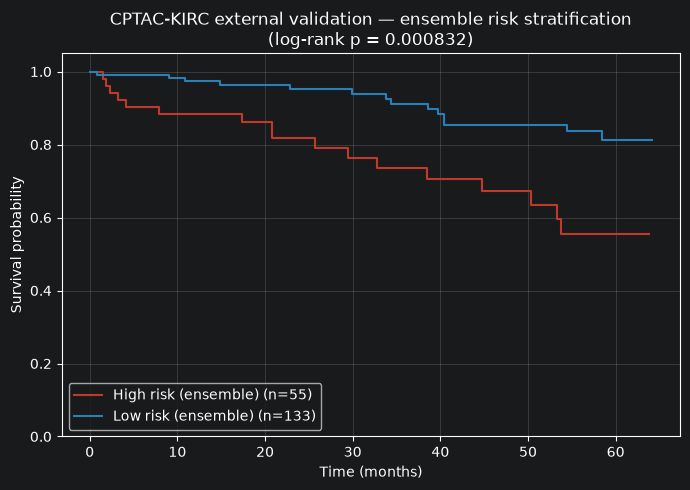

KM plot -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\external_validation_cptac\cptac_km_ensemble.png
Per-fold results table -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\external_validation_cptac\tables\cptac_external_validation_results.csv
Per-patient ensemble risk scores -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\external_validation_cptac\tables\cptac_ensemble_risk_scores.csv
Audit YAML -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\audit\phase9_external_validation_cptac.yaml

PHASE 9 COMPLETE — CPTAC EXTERNAL VALIDATION
  Ensemble C-index : 0.7073  95% CI [0.5984, 0.8054]
  Log-rank p       : 0.000832
  Per-fold mean C-index : 0.7032 +/- 0.0342


In [10]:
import matplotlib.pyplot as plt

def km_curve(times, events):
    '''Simple KM estimator for plotting (Nelson-Aalen product-limit).'''
    order = np.argsort(times)
    t_s, e_s = times[order], events[order]
    uniq_t = np.unique(t_s)
    surv = 1.0
    xs, ys = [0.0], [1.0]
    n = len(t_s)
    for t in uniq_t:
        at_risk = (t_s >= t).sum()
        d = ((t_s == t) & (e_s == 1)).sum()
        if at_risk > 0 and d > 0:
            surv *= (1 - d / at_risk)
        xs.append(t)
        ys.append(surv)
    return np.array(xs), np.array(ys)

fig, ax = plt.subplots(figsize=(7, 5))
for mask, label, color in [(ens_hi_mask, 'High risk (ensemble)', '#c0392b'),
                            (~ens_hi_mask, 'Low risk (ensemble)', '#2980b9')]:
    xs, ys = km_curve(cptac_times[mask], cptac_events[mask])
    ax.step(xs, ys, where='post', label=f"{label} (n={int(mask.sum())})", color=color)
ax.set_xlabel('Time (months)')
ax.set_ylabel('Survival probability')
ax.set_title(f'CPTAC-KIRC external validation — ensemble risk stratification\n(log-rank p = {ens_logrank_p:.3g})')
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
km_plot_path = EXTVAL_DIR / 'cptac_km_ensemble.png'
fig.savefig(km_plot_path, dpi=150)
plt.show()
print(f"KM plot -> {km_plot_path}")

# ── Save results table ────────────────────────────────────────────────────────
results_path = EXTVAL_TABLE_DIR / 'cptac_external_validation_results.csv'
results_df.to_csv(results_path, index=False)
print(f"Per-fold results table -> {results_path}")

ensemble_df = pd.DataFrame([{
    'patient_id': p, 'ensemble_risk': r, 'os_months': t, 'event': e,
    'high_risk': bool(h)
} for p, r, t, e, h in zip(cptac_patients, ensemble_risk, cptac_times, cptac_events, ens_hi_mask)])
ensemble_path = EXTVAL_TABLE_DIR / 'cptac_ensemble_risk_scores.csv'
ensemble_df.to_csv(ensemble_path, index=False)
print(f"Per-patient ensemble risk scores -> {ensemble_path}")

# ── Audit YAML ─────────────────────────────────────────────────────────────────
audit = {
    'phase'    : 'Phase 9 — External Validation on CPTAC-KIRC',
    'timestamp': datetime.now().isoformat(),

    'cohort': {
        'n_cptac_patients' : len(cptac_patients),
        'n_events'         : int(cptac_events.sum()),
        'n_censored'       : int((cptac_events == 0).sum()),
        'ppi_genes_in_cptac_rna_pct': round(float(ppi_in_cptac_vst / n_nodes * 100), 1),
        'ppi_genes_in_cptac_cnv_pct': round(float(ppi_in_cptac_cnv / n_nodes * 100), 1),
        'cnv_neutral_conversion': f'raw - {CPTAC_CNV_NEUTRAL_VALUE}, clipped to {GISTIC2_CLIP_RANGE}',
        'patients_dropped_no_cnv_data': dropped_no_cnv,
        'cnv_rna_aliquot_mismatch_n': len(cnv_aliquot_substitutions),
        'cnv_rna_aliquot_mismatch_detail': {
            pat: {'rna_sid': info['rna_sid'], 'cnv_col': info['cnv_col'],
                  'cnv_col_tissue_type': info['cnv_col_tissue_type']}
            for pat, info in cnv_aliquot_substitutions.items()
        },
    },

    'methodology': {
        'normalisation'  : 'All RNA z-score / CNV centering / clinical stats fit on '
                            'each TCGA fold\'s TRAINING split only, then applied to CPTAC. '
                            'No statistic was ever fit on CPTAC.',
        'ppi_edges'      : 'Each fold\'s own TCGA train-fold Pearson-pruned PPI edges reused as-is.',
        'baseline_hazard': 'Breslow baseline hazard + censoring KM fit on each fold\'s TCGA train split.',
        'risk_threshold' : 'Median split threshold fit on each fold\'s TCGA train risks.',
    },

    'per_fold_results': {
        'mean_ext_cindex': round(float(cindices.mean()), 4),
        'std_ext_cindex' : round(float(cindices.std()), 4),
        'mean_ext_ibs'   : round(float(ibs_vals.mean()), 4),
        'mean_ext_iauc'  : round(float(iauc_vals.mean()), 4),
        'logrank_folds_significant': f"{n_significant}/{len(results_df)}",
        'logrank_fisher_combined_p': round(float(fisher_p), 6),
    },

    'ensemble_result': {
        'n_patients'     : len(cptac_patients),
        'cindex'         : round(float(ens_cindex), 4),
        'ci_95'          : [round(ens_ci_lo, 4), round(ens_ci_hi, 4)],
        'n_high_risk'    : int(ens_hi_mask.sum()),
        'n_low_risk'     : int((~ens_hi_mask).sum()),
        'logrank_chi2'   : round(float(ens_chi2), 4),
        'logrank_p'      : round(float(ens_logrank_p), 6),
    },

    'reference_internal_tcga_cindex': 0.755,

    'outputs': {
        'per_fold_table'  : str(results_path),
        'ensemble_scores' : str(ensemble_path),
        'km_plot'         : str(km_plot_path),
    },

    'status': 'COMPLETE',
}

audit_path = AUDIT_DIR / 'phase9_external_validation_cptac.yaml'
with open(audit_path, 'w', encoding='utf-8') as f:
    yaml.dump(audit, f, default_flow_style=False, sort_keys=False)
print(f"Audit YAML -> {audit_path}")

print()
print("=" * 55)
print("PHASE 9 COMPLETE — CPTAC EXTERNAL VALIDATION")
print("=" * 55)
print(f"  Ensemble C-index : {ens_cindex:.4f}  95% CI [{ens_ci_lo:.4f}, {ens_ci_hi:.4f}]")
print(f"  Log-rank p       : {ens_logrank_p:.3g}")
print(f"  Per-fold mean C-index : {cindices.mean():.4f} +/- {cindices.std():.4f}")
